In [6]:
%gui wx
import sys
import os
import os.path as op

PROJECT_DIR = '/data/NSSP'
os.chdir(PROJECT_DIR)
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.list()

loadFSL()

import fsl.wrappers
from fsl.wrappers import fslmaths, mcflirt, fast, bet, flirt
from fsl.wrappers.misc import fslroi

import glob
import subprocess
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import plotting, image

print("Working in:", os.getcwd())

Working in: /data/NSSP


In [16]:
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

In [9]:
DATA_ROOT   = op.join(PROJECT_DIR, 'Data')
T1_PATH     = op.join(DATA_ROOT, 'T1', 'T1w.nii.gz')
FMRI_DIR    = op.join(DATA_ROOT, 'fMRI', 'tfMRI_LANGUAGE_LR')
FMRI_PATH   = op.join(FMRI_DIR, 'tfMRI_LANGUAGE_LR.nii.gz')
EVENTS_PATH = op.join(FMRI_DIR, 'tfMRI_LANGUAGE_LR_task_onsets.csv')

PREPROCESS_DATA_ROOT = op.join(PROJECT_DIR, 'derivatives', 'preprocessed_data')
FIG_DIR = op.join(PROJECT_DIR, 'figures')
mkdir_no_exist(op.join(PROJECT_DIR, 'derivatives'))
mkdir_no_exist(PREPROCESS_DATA_ROOT)
mkdir_no_exist(FIG_DIR)


In [10]:
DATA_ROOT = op.join(PROJECT_DIR, 'Data')
T1_PATH = op.join(DATA_ROOT, 'T1', 'T1w.nii.gz')

## 1. Structural preprocessing

### 1a. Skull-stripping with `BET`


In [17]:
def skull_stripped(t1_path, preproc_root, robust=False):
    """
    Perform skull stripping on a T1w anatomical image with FSL BET and save the outputs in preproc_root.

    Args:
        t1_path (str): Full path to the input T1w image (.nii.gz).
        preproc_root (str): Path to the directory where the skull-stripped brain and its mask are saved.
        robust (bool): Whether to use robust brain centre estimation (-R) in BET.
            Outputs are named 'T1w_stripped_robust' if True, 'T1w_stripped' otherwise.

    Returns:
        tuple of str: Paths to the skull-stripped brain and to its binary mask.
    """
    name = 'T1w_stripped_robust' if robust else 'T1w_stripped'
    betted_brain_path = op.join(preproc_root, name)
    os.system(f'bet {t1_path} {betted_brain_path} -m {"-R" if robust else ""}')
    print("Done with BET:", betted_brain_path)
    return betted_brain_path + '.nii.gz', betted_brain_path + '_mask.nii.gz'

#### Default BET parameters

In [18]:
brain_default, mask_default = skull_stripped(T1_PATH, PREPROCESS_DATA_ROOT)

Done with BET: /data/NSSP/derivatives/preprocessed_data/T1w_stripped


In [19]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(T1_PATH)
fsleyesDisplay.load(mask_default)

#### Robust brain centre estimation (`-R`)


In [20]:
brain_robust, mask_robust = skull_stripped(T1_PATH, PREPROCESS_DATA_ROOT, robust=True)

Done with BET: /data/NSSP/derivatives/preprocessed_data/T1w_stripped_robust


In [21]:
# Compare masks
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(T1_PATH)
fsleyesDisplay.load(mask_default)
fsleyesDisplay.load(mask_robust)

#### Report figure: original image vs skull-stripped T1w brain

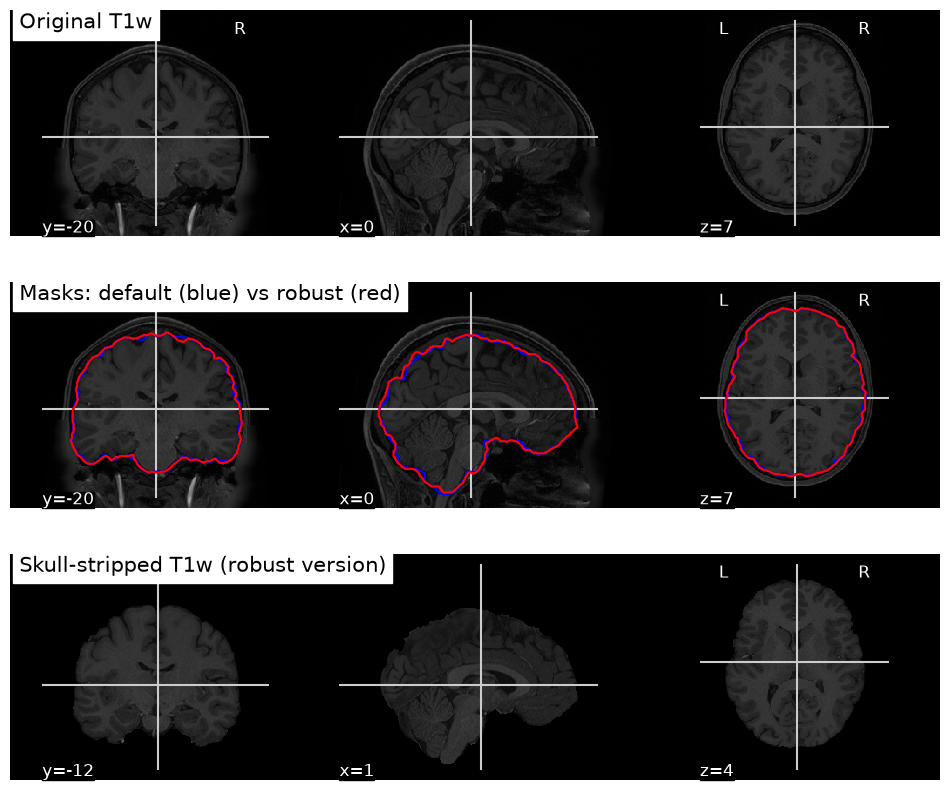

In [22]:
# we keep the robust version
bet_path, resulting_mask_path = brain_robust, mask_robust

FIG_DIR = op.join(PROJECT_DIR, 'figures')
mkdir_no_exist(FIG_DIR)

fig, axes = plt.subplots(3, 1, figsize=(12, 10))
plotting.plot_anat(T1_PATH, title='Original T1w', axes=axes[0])
d = plotting.plot_anat(T1_PATH, title='Masks: default (blue) vs robust (red)', axes=axes[1])
d.add_contours(mask_default, levels=[0.5], colors='b')
d.add_contours(mask_robust, levels=[0.5], colors='r')
plotting.plot_anat(bet_path, title='Skull-stripped T1w (robust version)', axes=axes[2])

fig.savefig(op.join(FIG_DIR, '1a_skullstrip.png'), dpi=200, bbox_inches='tight')
plt.show()